In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from forestgap import Proximity
from forestgap.manifold import phate
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns
import numpy as np

# Convert treeData to a pandas DataFrame
treeData = pd.read_csv("../datasets/treeData.csv")
treeData = pd.DataFrame(treeData)
X = treeData.drop(columns=["branch"])
y = treeData["branch"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

In [14]:
%matplotlib inline

In [15]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, oob_score = True)
rfProx = Proximity(rf)

In [16]:
rfProx.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [17]:
prox_oob_matches = (rfProx.oob_decision_function_.argmax(axis=1) == rfProx.prox_predict().argmax(axis=1))


In [19]:
np.where(~prox_oob_matches)

(array([273, 707, 793]),)

In [32]:
print(rfProx.oob_decision_function_[273, :])
print(rfProx.prox_predict()[273])

[0.         0.         0.         0.44117647 0.         0.02941176
 0.08823529 0.44117647 0.         0.        ]
[0.         0.         0.         0.44117647 0.         0.02941176
 0.08823529 0.44117647 0.         0.        ]


In [34]:
print(rfProx.oob_decision_function_[707, :])
print(rfProx.prox_predict()[707])

[0.         0.40740741 0.         0.18518519 0.40740741 0.
 0.         0.         0.         0.        ]
[0.         0.4074074  0.         0.18518519 0.40740741 0.
 0.         0.         0.         0.        ]


In [35]:
print(rfProx.oob_decision_function_[793, :])
print(rfProx.prox_predict()[793])

[0.  0.  0.5 0.  0.  0.  0.  0.  0.5 0. ]
[0.  0.  0.5 0.  0.  0.  0.  0.  0.5 0. ]


In [6]:
emb = phate.fit_phate_from_forest(rfProx)

Calculating PHATE...
  Running PHATE on precomputed affinity matrix with 1008 observations.
  Calculating graph and diffusion operator...
  Calculated graph and diffusion operator in 0.01 seconds.
  Calculating optimal t...
    Automatically selected t = 13
  Calculated optimal t in 0.42 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.09 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.3% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 1.12 seconds.
Calculated PHATE in 1.66 seconds.


<Axes: >

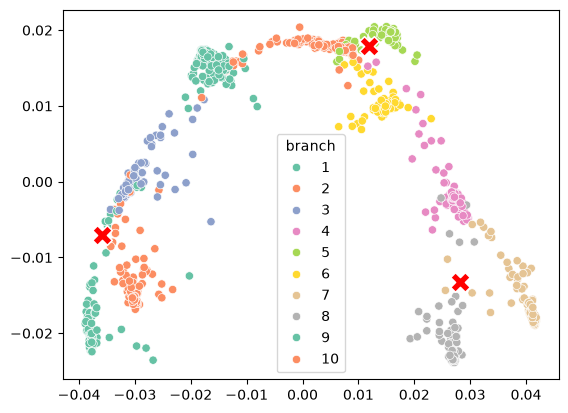

In [8]:
matches_mask = rfProx.oob_decision_function_.argmax(axis=1) == rfProx.prox_predict().argmax(axis=1)

sns.scatterplot(x=emb[matches_mask, 0], y=emb[matches_mask, 1], hue=y_train[matches_mask], palette="Set2")
sns.scatterplot(x=emb[~matches_mask, 0], y=emb[~matches_mask, 1], color="red", marker="X", s=200, legend=False)